# 6 · Phase 5 follow-ups: the last 11 °C, coarse-model fronts, the stress limit and a second temperature check

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, Milford, Utah (USA)**

Notebook 4 left four questions. The owner's decisions on them set this notebook's questions:

1. **The last +11 °C.** After the wellbore model, the reservoir model is still about 11 °C too hot at the 16B bottom hole. Do thin, fast fracture paths where water and rock are *not* at one temperature (local thermal non-equilibrium, LTNE) explain it? We report the answer either way.
2. **Coarse-model fronts.** KAI flow upscaling fixes the 30-year heat on 70 m cells but not the early breakthrough. Does a front correction from the fine model's flow field fix it? A pass rule is set *before* the benchmark; until it passes, the case page states only the 30-year heat for coarse models.
3. **The stress limit.** Is there an open local Shmin at 16A to test feasibility against, beside the GDR 1222 gradient?
4. **A second temperature check.** Does the GDR 1608 pressure–temperature gauge in 16B agree with the temperature model (notebook 1)?

**New data** (DOE Geothermal Data Repository, CC BY 4.0, licence read on each GDR page on 30 October 2026; SHA-256 in `DATA.md`; only derived values in `data/`):
* **GDR 1608** (DOI [10.15121/2368548](https://doi.org/10.15121/2368548)): Baker Hughes P–T gauge on the fibre in 16B(78)-32, 7,056.67 ft MD, 26 March – 20 April 2024.
* **GDR 1596**: Battelle report on the 16B(78)-32 minifrac tests (June–July 2023, 5,202–5,966 ft TVD). Interpreted Shmin gradients are quoted from it.
* **GDR 1408**: CSM slides on the 16A(78)-32 stage 1 pressure falloff (April 2022). Quoted for its finding that no closure was seen.

*Credit: Utah FORGE, U.S. Department of Energy, via the Geothermal Data Repository (OpenEI), CC BY 4.0.*

**Labels.** Every model number is **simulated** by the KAI Reservoir Lab engine (`results/kai_engine_phase5.json`, `kai-engine reference forge-phase5`). The phase 4 members are re-run unchanged (same parameters and calibrated apertures), so each section changes one thing.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, GRANITE, BLUE, GREY = "#c9a227", "#26292e", "#b5838d", "#2a78d6", "#8a8f98"     # KAI energy palette
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase5.json").read_text())      # KAI engine run (simulated)
P4 = json.loads(pathlib.Path("results/kai_engine_phase4.json").read_text())
def pct(d, f="{:.1f}"):
    return f"{f.format(d['P50'])} ({f.format(d['P10'])} to {f.format(d['P90'])})"
def p3(v):
    v = np.asarray([x for x in v if x is not None and np.isfinite(x)], float)
    return {"P10": float(np.percentile(v, 10)), "P50": float(np.percentile(v, 50)), "P90": float(np.percentile(v, 90))}
print(E["label"]); print("sources:", ", ".join(f"GDR {s['gdr']} ({s['licence']})" for s in E["sources"].values()))

simulated (KAI engine TPFA solver); measured values are labelled measured
sources: GDR 1608 (CC BY 4.0), GDR 1596 (CC BY 4.0), GDR 1408 (CC BY 4.0)


## 1 · The last 11 °C: local thermal non-equilibrium

**The model.** The phase 4 model assumes that in each 35 m cell the water and all the rock are at one temperature. The dual-continuum model keeps the water in the fractures as one unknown and the rock between the fractures as eight nested shells (MINC), with 1-D conduction from the fracture face into the block. The flowing-fracture spacing in each cell is 1 / P32 of the stimulated fracture network (GDR 1646), times an uncertain multiplier (log-uniform 0.5–2) per member. The rock's own pore water stays with the rock, so the total heat in place is the same as before. The solver is checked against Lauwerier's solution for one fracture, against the equilibrium limit and for energy balance (kai-engine tests).

**The test.** The August 2024 circulation test of notebook 4 (Barton–Bandis apertures), with the same members, once with equilibrium and once with the dual continuum.

,model,"16B bottom hole, °C","misfit vs implied, °C"
0,equilibrium (phase 4),214.1 (212.6 to 215.5),+11.2 (+9.7 to +12.6)
1,dual continuum (phase 5),208.4 (203.0 to 214.0),+5.5 (+0.1 to +11.1)


implied by the measured wellhead temperature: 202.9 (200.0 to 205.9) °C; members 20/20
dual continuum minus equilibrium: -5.6 (-11.6 to -0.4) °C; rank correlation with the spacing multiplier -0.48
stimulated-fracture spacing (median per member): 38 (21 to 71) m
30 years at 10 kg/s: year-30 temperature 128.1 (122.3 to 144.1) → 127.3 (121.9 to 141.7) °C (change -0.9 (-2.4 to -0.3) °C); breakthrough 1.77 (1.10 to 2.55) → 0.47 (0.22 to 0.99) years


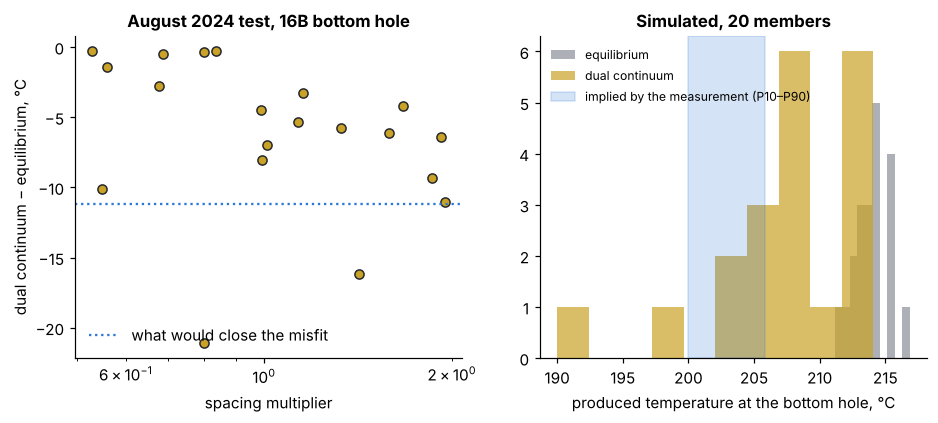

In [2]:
L = E["ltne"]["summary"]
imp = P4["wellbore"]["T_bottom_implied_c"]
rows = [{"model": "equilibrium (phase 4)", "16B bottom hole, °C": pct(L["T_bottomhole_lte_c"]), "misfit vs implied, °C": pct(L["misfit_lte_c"], "{:+.1f}")},
        {"model": "dual continuum (phase 5)", "16B bottom hole, °C": pct(L["T_bottomhole_ltne_c"]), "misfit vs implied, °C": pct(L["misfit_ltne_c"], "{:+.1f}")}]
display(pd.DataFrame(rows))
print(f"implied by the measured wellhead temperature: {pct(imp)} °C; members {L['ok']}/{L['members']}")
print(f"dual continuum minus equilibrium: {pct(L['ltne_minus_lte_c'], '{:+.1f}')} °C; rank correlation with the spacing multiplier {L.get('spearman_effect_vs_spacing', float('nan')):+.2f}")
print(f"stimulated-fracture spacing (median per member): {pct(L['spacing_stimulated_P50_m'], '{:.0f}')} m")
F = L["forecast"]["10"]
print(f"30 years at 10 kg/s: year-30 temperature {pct(F['T_prod_end_c_lte'])} → {pct(F['T_prod_end_c_ltne'])} °C (change {pct(F['T30_change_c'], '{:+.1f}')} °C); "
      f"breakthrough {pct(F['breakthrough_years_lte'], '{:.2f}')} → {pct(F['breakthrough_years_ltne'], '{:.2f}')} years")
mem = [m for m in E["ltne"]["members"] if m.get("ok")]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
d = np.array([m["validation_ltne"]["produced_T_bottomhole_c"] - m["validation_lte"]["produced_T_bottomhole_c"] for m in mem])
s = np.array([m["spacing_mult"] for m in mem])
ax[0].scatter(s, d, color=GOLD, edgecolor=CHARCOAL); ax[0].set_xscale("log"); ax[0].set_xlabel("spacing multiplier"); ax[0].set_ylabel("dual continuum − equilibrium, °C")
ax[0].axhline(-(L["misfit_lte_c"]["P50"]), color=BLUE, ls=":", label="what would close the misfit"); ax[0].legend(); ax[0].set_title("August 2024 test, 16B bottom hole")
for k, c, lab in (("lte", GREY, "equilibrium"), ("ltne", GOLD, "dual continuum")):
    v = [m[f"validation_{k}"]["produced_T_bottomhole_c"] for m in mem]
    ax[1].hist(v, bins=10, color=c, alpha=.7, label=lab)
ax[1].axvspan(imp["P10"], imp["P90"], color=BLUE, alpha=.2, label="implied by the measurement (P10–P90)")
ax[1].set_xlabel("produced temperature at the bottom hole, °C"); ax[1].legend(fontsize=8); ax[1].set_title("Simulated, 20 members")
fig.savefig("figures/forge_ltne.png"); plt.show()

### Refitted to the August pressures

The dual-continuum model leaves the water near 16A colder, so more viscous, and the injector pressure rises. Every phase 4 member was fitted to the August pressure difference; here each dual-continuum member is refitted the same way (its stimulated-aperture factor), and the August test is run again.

In [3]:
R = E["ltne_recalibrated"]["summary"]
print(f"aperture factor, refitted / phase 4: {pct(R['aperture_factor_ratio'], '{:.2f}')}")
print(f"injector bottom-hole pressure in the window: equilibrium {pct(L['injector_bhp_lte_mpa'], '{:.1f}')}, dual continuum {pct(L['injector_bhp_ltne_mpa'], '{:.1f}')}, "
      f"refitted {pct(R['injector_bhp_ltne_mpa'], '{:.1f}')} MPa (measured, through the wellbore model: {P4['wellbore']['injector_bhp_mpa']['P50']:.2f})")
print(f"16B bottom hole, refitted dual continuum: {pct(R['T_bottomhole_ltne_c'])} °C; misfit {pct(R['misfit_ltne_c'], '{:+.1f}')} °C")
F = R["forecast"]["10"]
print(f"30 years at 10 kg/s ({F['members']} members): year-30 change {pct(F['T30_change_c'], '{:+.1f}')} °C; breakthrough {pct(F['breakthrough_years_ltne'], '{:.2f}')} years")

aperture factor, refitted / phase 4: 1.13 (1.07 to 1.17)
injector bottom-hole pressure in the window: equilibrium 42.2 (41.8 to 42.6), dual continuum 48.5 (45.9 to 50.4), refitted 42.3 (42.1 to 42.7) MPa (measured, through the wellbore model: 42.85)
16B bottom hole, refitted dual continuum: 207.4 (200.7 to 213.7) °C; misfit +4.5 (-2.2 to +10.8) °C
30 years at 10 kg/s (6 members): year-30 change -3.1 (-6.0 to -1.4) °C; breakthrough 0.46 (0.21 to 0.89) years


**Reading.** With the same apertures the dual-continuum model cools the 16B bottom hole by -5.6 (-11.6 to -0.4) °C, which halves the misfit (+11.2 → +5.5 (+0.1 to +11.1) °C). But it also leaves cold, viscous water near 16A, and the injector pressure rises from 42.2 to 48.5 MPa (measured 42.85). Refitted to the August pressures (apertures × 1.13), it holds the pressure (42.3 MPa) and leaves a misfit of **+4.5 (-2.2 to +10.8) °C**. So local thermal non-equilibrium explains a little over half of the last 11 °C. The rest is the size of the temperature-model bias that section 4 finds at 16B (about +6 °C). Over 30 years at 10 kg/s the refitted model ends -3.1 (-6.0 to -1.4) °C cooler than the equilibrium model (6 members); the first 5 % cooling arrives after 0.46 (0.21 to 0.89) years instead of 1.77 (1.10 to 2.55): thin, fast paths cool first, the bulk of the heat is unchanged.

## 2 · Coarse-model fronts: the time-of-flight correction

**The correction.** The KAI upscaling already solves the fine model's steady flow with the wells. On that field, and on the coarse model's own field, a cold step is carried by advection only, slowed by the rock's heat capacity (retardation R = (ρc)bulk / (ρc)water). The time for 5 % of it to reach 16B is the thermal time of flight τ. The corrected coarse breakthrough is the coarse model's breakthrough × τ(fine) / τ(coarse). No fine heat run is needed.

**The pass rule, set before the run.** At both 10 and 40 kg/s, over the 12 phase 4 upscaling members: the median |error| against the fine (23.3 m) breakthrough is at most 15 %, and the P10 and P90 errors are within ±30 %.

,rate,coarse model,"error, raw (%)","error, corrected (%)"
0,10 kg/s,"KAI upscaled, 70 m",+54 (-26 to +115),-20 (-24 to -13)
1,10 kg/s,"usual Oda + Peaceman, 70 m",+25 (-32 to +62),-27 (-32 to -25)
2,40 kg/s,"KAI upscaled, 70 m",+72 (-16 to +141),-11 (-18 to -3)
3,40 kg/s,"usual Oda + Peaceman, 70 m",+39 (-26 to +84),-16 (-26 to -15)


KAI, 10 kg/s: median |error| 20 %, P10 -24 %, P90 -13 % → fail
KAI, 40 kg/s: median |error| 11 %, P10 -18 %, P90 -3 % → pass
verdict (KAI coarse model): FAIL | usual coarse model: FAIL
sensitivity, arrival fraction 0.01: KAI pass = False
sensitivity, arrival fraction 0.1: KAI pass = False


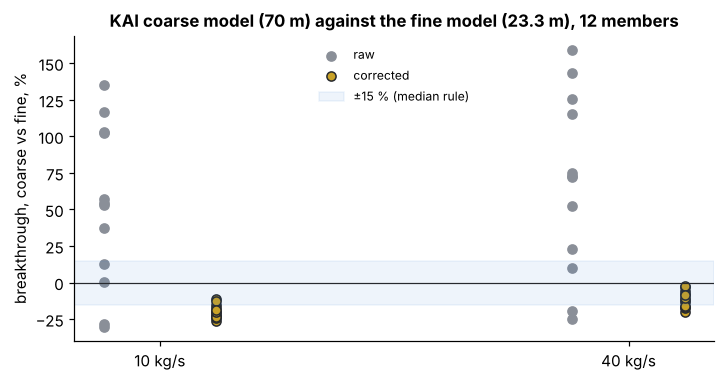

In [4]:
FC = E["front_correction"]
B = FC["benchmark"]["0.05"]
rows = []
for q, d in B["rates"].items():
    for m, lab in (("coarse_kai", "KAI upscaled, 70 m"), ("coarse_usual", "usual Oda + Peaceman, 70 m")):
        rows.append({"rate": f"{q} kg/s", "coarse model": lab, "error, raw (%)": pct({k: 100 * v for k, v in d[m]['err_raw'].items() if k in ('P10', 'P50', 'P90')}, '{:+.0f}'),
                     "error, corrected (%)": pct({k: 100 * v for k, v in d[m]['err_corrected'].items() if k in ('P10', 'P50', 'P90')}, '{:+.0f}')})
display(pd.DataFrame(rows))
V = FC["verdict"]
for q, c in V["by_rate"].items():
    print(f"KAI, {q} kg/s: median |error| {100 * c['median_abs']:.0f} %, P10 {100 * c['P10']:+.0f} %, P90 {100 * c['P90']:+.0f} % → {'pass' if c['pass'] else 'fail'}")
print("verdict (KAI coarse model):", "PASS" if V["pass"] else "FAIL", "| usual coarse model:", "PASS" if FC["verdict_usual"]["pass"] else "FAIL")
for e in ("0.01", "0.1"):
    print(f"sensitivity, arrival fraction {e}: KAI pass = {FC['benchmark'][e] and all(abs(FC['benchmark'][e]['rates'][q]['coarse_kai']['err_corrected']['P50']) <= 0.15 for q in FC['benchmark'][e]['rates'])}")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
rws = B["rows"]
for i, q in enumerate(("10", "40")):
    rr = [r for r in rws if r["rate"] == q]
    ax.scatter(np.full(len(rr), i - 0.12), [100 * r["coarse_kai"]["err_raw"] for r in rr], color=GREY, label="raw" if i == 0 else None)
    ax.scatter(np.full(len(rr), i + 0.12), [100 * r["coarse_kai"]["err_corrected"] for r in rr], color=GOLD, edgecolor=CHARCOAL, label="corrected" if i == 0 else None)
ax.axhspan(-15, 15, color=BLUE, alpha=.08, label="±15 % (median rule)"); ax.axhline(0, color=CHARCOAL, lw=.8)
ax.set_xticks([0, 1], ["10 kg/s", "40 kg/s"]); ax.set_ylabel("breakthrough, coarse vs fine, %"); ax.legend(fontsize=8)
ax.set_title("KAI coarse model (70 m) against the fine model (23.3 m), 12 members"); fig.savefig("figures/forge_front_correction.png"); plt.show()

**Reading: the correction fails the rule set in advance.** It removes most of the scatter (KAI, 10 kg/s: raw +54 (-26 to +115) % → corrected -20 (-24 to -13) %), but it leaves the corrected breakthrough 10–20 % early, and the 10 kg/s median misses the 15 % limit. The bias has one sign, so a calibrated factor may pass, but it would have to be tested on members it was not fitted to. Until then the case page states only the 30-year heat for coarse models.

## 3 · The stress limit: is there a local Shmin at 16A?

* **16A, GDR 1408.** The stage 1 step-rate test of April 2022 is the only falloff at 16A in the open data. Its G-function analysis found **no closure stress** (the authors suggest reopened natural fractures that did not close). So there is no local Shmin at 16A to use.
* **16B, GDR 1596.** Seven minifracs at 5,202–5,966 ft TVD (1.59–1.82 km), above the reservoir section. The report's best Shmin gradient is **0.60 psi/ft** (13.6 MPa/km) without adjustment; adjusted for the cooling before the tests, **0.80 psi/ft** (mid) to **0.94 psi/ft** (high).
* We test feasibility against each, extrapolated to the top completion of 16A, beside the GDR 1222 recommended gradient (17.0 MPa/km). Each scenario sets both the feasibility limit and the stress that closes the Barton–Bandis fractures. 8 members, rates 5, 10 and 20 kg/s.

In [5]:
S = E["shmin"]["summary"]
rows = [{"Shmin source": k, "gradient, MPa/km": f"{v['gradient_mpa_per_km']:.1f}", "Shmin at 16A top, MPa": f"{v['shmin_top_16A_mpa']:.1f}",
         "highest rate, kg/s": pct(v["max_feasible_rate_kg_s"]), "feasible members at 5/10/20 kg/s": " / ".join(str(v["feasible_members"][q]) for q in ("5", "10", "20"))}
        for k, v in S["scenarios"].items()]
display(pd.DataFrame(rows))
print(f"August 2024 injector bottom-hole pressure (wellbore model): {S['august_injector_bhp_mpa']:.2f} MPa")

,Shmin source,"gradient, MPa/km","Shmin at 16A top, MPa","highest rate, kg/s",feasible members at 5/10/20 kg/s
0,gdr1222_recommended,17.0,40.3,9.6 (9.3 to 10.2),8 / 2 / 0
1,gdr1596_unadjusted,13.6,32.2,0.0 (0.0 to 5.4),2 / 0 / 0
2,gdr1596_cooling_mid,18.1,42.9,11.8 (11.6 to 12.3),8 / 8 / 0
3,gdr1596_cooling_high,21.3,50.5,16.2 (15.8 to 16.9),8 / 8 / 0


August 2024 injector bottom-hole pressure (wellbore model): 42.85 MPa


**Reading.** The result turns on the minifracs' cooling adjustment. As measured (0.60 psi/ft) the limit at 16A is 32.2 MPa, lower than the August test's 42.9 MPa, and no member can run 10 kg/s. With the report's mid adjustment (0.80 psi/ft) the highest rate is 11.8 (11.6 to 12.3) kg/s, and with the high one 16.2 (15.8 to 16.9) kg/s, against 9.6 (9.3 to 10.2) kg/s with GDR 1222. A minifrac in the reservoir section of 16A would settle it.

## 4 · A second temperature check: the GDR 1608 gauge in 16B

The gauge sits at 7,056.67 ft MD in 16B. Its record has two parts:
* **26 March – 2 April 2024:** a quiet well warming back after it was cooled during completion and the fibre installation.
* **From 03:00 on 3 April:** the 16A stimulation. Pressure at the gauge jumps by up to 3,200 psi and the temperature swings by about ±15 °C.

The logger changes units on 2 April (171.9 → 341.6 within an hour at constant pressure: the same temperature in °F); every reading from then on is converted. The static temperature lies above the last quiet reading. We estimate it with a recovery fit, T(t) = T∞ − B / (t − t0), over the quiet part.

gauge: 2151 m MD, 2043 m TVD
last quiet day 171.9 °C, still warming 0.49 °C/day
recovery fit: T_inf 177.9 °C (range 174.2–194.4 for fits within 25 % of the best RMSE 0.63 °C)
model (GDR 1205) at the gauge 183.6 °C (within 50 m: 179.4–187.9)
model minus measured: +5.7 °C against the fit (-10.8 to +9.5); +11.7 °C against the last quiet reading (an upper bound)


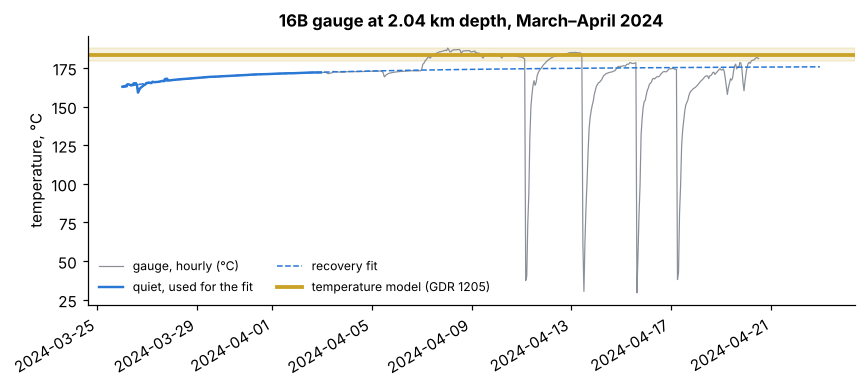

In [6]:
g = E["geotherm_1608"]
pt = pd.read_csv("data/pt_16B_gdr1608_hourly.csv", parse_dates=["time"])
quiet = pt[pt.quiet]
t = (quiet.time - pt.time.iloc[0]).dt.total_seconds().values / 86400; Tq = quiet.T_c.values
best = None
for t0 in -np.geomspace(0.25, 120.0, 200):
    x = 1 / (t - t0); A = np.c_[np.ones_like(x), -x]; c, *_ = np.linalg.lstsq(A, Tq, rcond=None)
    rmse = float(np.sqrt(np.mean((A @ c - Tq) ** 2)))
    if c[1] > 0 and (best is None or rmse < best[0]): best = (rmse, float(c[0]), float(t0), float(c[1]))
fit = g["measured"]["recovery_fit"]
assert abs(best[1] - fit["T_inf_c"]) < 0.05 and abs(best[0] - fit["rmse_c"]) < 0.01      # same fit as the engine
print(f"gauge: {g['gauge_md_m']:.0f} m MD, {g['gauge_tvd_m']:.0f} m TVD")
print(f"last quiet day {g['measured']['T_last_quiet_c']:.1f} °C, still warming {g['measured']['warming_c_per_day_at_end']:.2f} °C/day")
print(f"recovery fit: T_inf {fit['T_inf_c']:.1f} °C (range {fit['T_inf_range_c'][0]:.1f}–{fit['T_inf_range_c'][1]:.1f} for fits within 25 % of the best RMSE {fit['rmse_c']:.2f} °C)")
print(f"model (GDR 1205) at the gauge {g['model']['T_c']:.1f} °C (within 50 m: {g['model']['T_range_c'][0]:.1f}–{g['model']['T_range_c'][1]:.1f})")
print(f"model minus measured: {g['misfit_vs_recovery_c']:+.1f} °C against the fit ({g['misfit_vs_recovery_range_c'][0]:+.1f} to {g['misfit_vs_recovery_range_c'][1]:+.1f}); "
      f"{g['misfit_vs_last_quiet_c']:+.1f} °C against the last quiet reading (an upper bound)")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(pt.time, pt.T_c, color=GREY, lw=.8, label="gauge, hourly (°C)")
ax.plot(quiet.time, Tq, color=BLUE, lw=1.6, label="quiet, used for the fit")
tt = np.linspace(t.min(), t.max() + 20, 200); ax.plot(pt.time.iloc[0] + pd.to_timedelta(tt, unit="D"), best[1] - best[3] / (tt - best[2]), color=BLUE, ls="--", lw=1, label="recovery fit")
ax.axhline(g["model"]["T_c"], color=GOLD, lw=2.5, label="temperature model (GDR 1205)")
ax.axhspan(*g["model"]["T_range_c"], color=GOLD, alpha=.15)
ax.set_ylabel("temperature, °C"); ax.legend(fontsize=8, ncol=2); ax.set_title("16B gauge at 2.04 km depth, March–April 2024")
fig.autofmt_xdate(); fig.savefig("figures/forge_gdr1608_check.png"); plt.show()

**Reading.** The temperature model is about +6 °C too hot at the gauge (-11 to +9 °C; at most +12 °C, against the last quiet reading). That is the size of what is left of the produced-temperature misfit after the dual-continuum model (section 1). The model was checked against 58-32 in notebook 1 (1.7 °C); at 16B, 300 m away, it may be a little hot. A static log in 16B over the open interval would test this directly.

## 5 · Published numbers

The case page and the session report quote the numbers below. The notebook stops if a re-run of the engine moves any of them by more than 2 %.

In [7]:
L, FC, S, g = E["ltne"]["summary"], E["front_correction"], E["shmin"]["summary"], E["geotherm_1608"]
now = {"ltne_T_bh_lte_P50": L["T_bottomhole_lte_c"]["P50"], "ltne_T_bh_ltne_P50": L["T_bottomhole_ltne_c"]["P50"],
       "ltne_misfit_lte_P50": L["misfit_lte_c"]["P50"], "ltne_misfit_ltne_P50": L["misfit_ltne_c"]["P50"],
       "ltne_misfit_ltne_P10": L["misfit_ltne_c"]["P10"], "ltne_misfit_ltne_P90": L["misfit_ltne_c"]["P90"],
       "ltne_change_P50": L["ltne_minus_lte_c"]["P50"], "ltne_change_P10": L["ltne_minus_lte_c"]["P10"], "ltne_change_P90": L["ltne_minus_lte_c"]["P90"],
       "ltne_T30_change_10_P50": L["forecast"]["10"]["T30_change_c"]["P50"],
       "ltne_bhp_lte_P50": L["injector_bhp_lte_mpa"]["P50"], "ltne_bhp_ltne_P50": L["injector_bhp_ltne_mpa"]["P50"],
       "ltne_refit_misfit_P50": E["ltne_recalibrated"]["summary"]["misfit_ltne_c"]["P50"],
       "ltne_refit_aperture_ratio_P50": E["ltne_recalibrated"]["summary"]["aperture_factor_ratio"]["P50"],
       "ltne_refit_bhp_P50": E["ltne_recalibrated"]["summary"]["injector_bhp_ltne_mpa"]["P50"],
       "front_pass": FC["verdict"]["pass"],
       "front_10_corrected_P50": FC["benchmark"]["0.05"]["rates"]["10"]["coarse_kai"]["err_corrected"]["P50"],
       "front_40_corrected_P50": FC["benchmark"]["0.05"]["rates"]["40"]["coarse_kai"]["err_corrected"]["P50"],
       "front_10_raw_P50": FC["benchmark"]["0.05"]["rates"]["10"]["coarse_kai"]["err_raw"]["P50"],
       "gdr1608_T_inf": g["measured"]["recovery_fit"]["T_inf_c"], "gdr1608_model": g["model"]["T_c"], "gdr1608_misfit": g["misfit_vs_recovery_c"]}
for k, v in S["scenarios"].items():
    now[f"shmin_{k}_maxrate_P50"] = v["max_feasible_rate_kg_s"]["P50"]
LR = E.get("ltne_recalibrated", {}).get("summary")
web = {"ltne": {"T_bh_lte": L["T_bottomhole_lte_c"], "T_bh_ltne": L["T_bottomhole_ltne_c"], "implied": P4["wellbore"]["T_bottom_implied_c"],
                "misfit_lte": L["misfit_lte_c"], "misfit_ltne": L["misfit_ltne_c"], "change": L["ltne_minus_lte_c"],
                "dp_change_mpa": L["injector_bhp_ltne_mpa"]["P50"] - L["injector_bhp_lte_mpa"]["P50"],
                "T30_change_10": L["forecast"]["10"]["T30_change_c"], "members": L["ok"],
                "refit": {"T_bh": LR["T_bottomhole_ltne_c"], "misfit": LR["misfit_ltne_c"], "aperture_ratio": LR["aperture_factor_ratio"],
                          "injector_bhp": LR["injector_bhp_ltne_mpa"], "T30_change_10": LR["forecast"]["10"]["T30_change_c"]} if LR else None},
       "front": {"rates": {q: {k: FC["benchmark"]["0.05"]["rates"][q]["coarse_kai"][k] for k in ("err_raw", "err_corrected")} for q in ("10", "40")},
                 "pass": FC["verdict"]["pass"], "members": FC["benchmark"]["0.05"]["members"]},
       "shmin": {"scenarios": {k: {"gradient_mpa_per_km": v["gradient_mpa_per_km"], "shmin_top_16A_mpa": v["shmin_top_16A_mpa"],
                                   "max_rate": v["max_feasible_rate_kg_s"], "feasible_members": v["feasible_members"]} for k, v in S["scenarios"].items()},
                 "members": S["ok"]},
       "geotherm": {"md_m": g["gauge_md_m"], "tvd_m": g["gauge_tvd_m"], "last_quiet_c": g["measured"]["T_last_quiet_c"],
                    "static_c": g["measured"]["recovery_fit"]["T_inf_c"], "static_range_c": g["measured"]["recovery_fit"]["T_inf_range_c"],
                    "model_c": g["model"]["T_c"], "model_range": g["model"]["T_range_c"], "misfit_c": g["misfit_vs_recovery_c"],
                    "misfit_range_c": g["misfit_vs_recovery_range_c"], "daily": g["daily"]}}
print(json.dumps(now, indent=1))

{
 "ltne_T_bh_lte_P50": 214.0574077171621,
 "ltne_T_bh_ltne_P50": 208.42580173345198,
 "ltne_misfit_lte_P50": 11.172836391230462,
 "ltne_misfit_ltne_P50": 5.541230407520345,
 "ltne_misfit_ltne_P10": 0.09308010708773279,
 "ltne_misfit_ltne_P90": 11.097027426287784,
 "ltne_change_P50": -5.583397151723318,
 "ltne_change_P10": -11.5890380185864,
 "ltne_change_P90": -0.36147407671748216,
 "ltne_T30_change_10_P50": -0.9378041575815388,
 "ltne_bhp_lte_P50": 42.193701060611986,
 "ltne_bhp_ltne_P50": 48.47020806481562,
 "ltne_refit_misfit_P50": 4.497224826195179,
 "ltne_refit_aperture_ratio_P50": 1.129506691958675,
 "ltne_refit_bhp_P50": 42.32198683156912,
 "front_pass": false,
 "front_10_corrected_P50": -0.20187158618180895,
 "front_40_corrected_P50": -0.11181081615389898,
 "front_10_raw_P50": 0.5395396276909319,
 "gdr1608_T_inf": 177.89946423831773,
 "gdr1608_model": 183.6354333045223,
 "gdr1608_misfit": 5.735969066204575,
 "shmin_gdr1222_recommended_maxrate_P50": 9.63264528411814,
 "shmin_gd

In [8]:
published = {'ltne_T_bh_lte_P50': 214.0574077171621, 'ltne_T_bh_ltne_P50': 208.42580173345198, 'ltne_misfit_lte_P50': 11.172836391230462, 'ltne_misfit_ltne_P50': 5.541230407520345, 'ltne_misfit_ltne_P10': 0.09308010708773279, 'ltne_misfit_ltne_P90': 11.097027426287784, 'ltne_change_P50': -5.583397151723318, 'ltne_change_P10': -11.5890380185864, 'ltne_change_P90': -0.36147407671748216, 'ltne_T30_change_10_P50': -0.9378041575815388, 'ltne_bhp_lte_P50': 42.193701060611986, 'ltne_bhp_ltne_P50': 48.47020806481562, 'ltne_refit_misfit_P50': 4.497224826195179, 'ltne_refit_aperture_ratio_P50': 1.129506691958675, 'ltne_refit_bhp_P50': 42.32198683156912, 'front_pass': False, 'front_10_corrected_P50': -0.20187158618180895, 'front_40_corrected_P50': -0.11181081615389898, 'front_10_raw_P50': 0.5395396276909319, 'gdr1608_T_inf': 177.89946423831773, 'gdr1608_model': 183.6354333045223, 'gdr1608_misfit': 5.735969066204575, 'shmin_gdr1222_recommended_maxrate_P50': 9.63264528411814, 'shmin_gdr1596_unadjusted_maxrate_P50': 0.0, 'shmin_gdr1596_cooling_mid_maxrate_P50': 11.835864029346311, 'shmin_gdr1596_cooling_high_maxrate_P50': 16.16395077849286}
for k, v in published.items():
    x = now[k]
    if isinstance(v, (str, bool)) or v is None or x is None:
        assert x == v, (k, x, v)
    else:
        assert abs(x - v) <= 0.02 * abs(v) + 0.01, (k, x, v)
pathlib.Path("results/nb6_phase5_followups.json").write_text(json.dumps({"published": now, "web": web}, indent=1))
print(f"all {len(published)} published numbers reproduced")

all 26 published numbers reproduced
